In [23]:
import numpy as np
import pandas as pd
import torch
from sklearn import preprocessing
import matplotlib.pyplot as plt

In [33]:
# Load the file using the path exactly as it was saved
file_path = 'embeddings_171225_2176_32768_blocks.28.mlp.l3' 
# file_path = 'embeddings_291225_2176_32768_blocks.28.mlp.l3_32768.pt'
data = torch.load(file_path, map_location=torch.device('cpu'))

# Extract the lists from the dictionary
ids = data["ids"]               # List of strings
# DeepPL files contains accession id without version number, so we need to erase it from our ids
ids = [item.split('.')[0] for item in ids] 
embeddings_list = data["embeddings"] # List of torch.Tensors

# Stack the list of tensors into one large tensor (N_samples x 4096)
embeddings_tensor = torch.stack(embeddings_list)

# Convert to Numpy array
loaded_embeds = embeddings_tensor.detach().cpu().numpy()
loaded_ids = np.array(ids)

print("Embeddings shape:", loaded_ids.shape)
print("Embeddings shape:", loaded_embeds.shape) 

df = pd.DataFrame(data=loaded_embeds[:,:],    # values
              index=loaded_ids[:],    # 1st column as index
              columns=[[f"feature_{i}" for i in range(len(loaded_embeds[0]))]]) 
# Take a look
df.head()

Embeddings shape: (2176,)
Embeddings shape: (2176, 4096)


,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,...,feature_4086,feature_4087,feature_4088,feature_4089,feature_4090,feature_4091,feature_4092,feature_4093,feature_4094,feature_4095
NC_012663,190.00,-378.0,-284.0,376.0,420.0000,-162.000,-472.0,171.00,-314.0,-1024.0,...,-170.000,134.0000,-246.0,-264.00,-260.00,322.000,350.0,-456.0,-266.00,-30.250
NC_025467,58.25,-94.0,-83.5,96.5,103.0000,-48.750,-115.5,43.75,-69.0,-276.0,...,-51.000,38.0000,-58.0,-56.75,-55.50,100.000,83.0,-121.0,-23.75,-24.125
AJ298298,80.00,-170.0,-140.0,364.0,-11.3125,-48.500,-360.0,41.75,-230.0,-392.0,...,-57.000,28.5000,-119.5,-111.50,-72.00,28.375,81.0,-306.0,-132.00,-10.875
NC_025436,580.00,-868.0,-556.0,840.0,904.0000,-276.000,-1000.0,364.00,-676.0,-2160.0,...,-438.000,318.0000,-516.0,-656.00,-524.00,912.000,936.0,-1080.0,38.00,-164.000
NC_018269,47.00,-79.0,-82.0,88.0,35.0000,-11.375,-112.5,28.00,-93.5,-171.0,...,-29.125,12.3125,-69.5,-52.25,-54.25,45.500,81.5,-107.0,-55.75,-21.375


In [34]:
# Training
sheet_names = pd.ExcelFile("journal.pcbi.1012525.s001.xlsx").sheet_names
# Training dataset
training = pd.read_excel("journal.pcbi.1012525.s001.xlsx", sheet_name=sheet_names[0])
# Test dataset
test = pd.read_excel("journal.pcbi.1012525.s001.xlsx", sheet_name=sheet_names[1])

# Create a dictionary mapping Accession ID -> Corrected Lifecycle
lifecycle_map = {}
all_metadata = pd.concat([training, test])

for _, row in all_metadata.iterrows():
    acc = row['Accession number']
    raw_life = row['Lifecycle']
    clean_life = "lysogenic" if str(raw_life).strip().lower() in ["lysogneic", "lysogenic"] else "lytic"
    lifecycle_map[acc] = clean_life

# Create aligned list
aligned_lifecycles = []
for accession in df.index:
    if accession in lifecycle_map:
        aligned_lifecycles.append(lifecycle_map[accession])
    else:
        # Warning only once per missing ID to avoid clutter
        print(f"Warning: Accession {accession} not found. Defaulting to lytic.")
        aligned_lifecycles.append("lytic") 

aligned_lifecycles = np.array(aligned_lifecycles)
print(f"Aligned labels length: {len(aligned_lifecycles)}")

Aligned labels length: 2176


In [ ]:
# Set global random state for following models
RANDOM_STATE = 0

# Load splits
sheet_names = pd.ExcelFile("journal.pcbi.1012525.s001.xlsx").sheet_names
training_df = pd.read_excel("journal.pcbi.1012525.s001.xlsx", sheet_name=sheet_names[0])
test_df = pd.read_excel("journal.pcbi.1012525.s001.xlsx", sheet_name=sheet_names[1])

train_ids = set(training_df['Accession number'].astype(str).str.strip())
test_ids = set(test_df['Accession number'].astype(str).str.strip())

# Prepare feature and labels
train_indices = []
test_indices = []
y_train = []
y_test = []

for i, accession in enumerate(df.index):
    label = lifecycle_map.get(accession, "lytic")
    
    if accession in train_ids:
        train_indices.append(i)
        y_train.append(label)
    elif accession in test_ids:
        test_indices.append(i)
        y_test.append(label)


X_train = df.iloc[train_indices]
X_test = df.iloc[test_indices]
y_train = np.array(y_train)
y_test = np.array(y_test)

# Scale data
scaler = preprocessing.StandardScaler()
scaler.fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

print(f"Data Split Loaded: {len(X_train)} Train, {len(X_test)} Test")


Data Split Loaded: 1804 Train, 372 Test


In [36]:
import numpy as np
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (confusion_matrix, accuracy_score, f1_score, 
                             matthews_corrcoef, make_scorer)
from sklearn.model_selection import TunedThresholdClassifierCV
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

# We tell the tuner: "Find the threshold that maximizes F1 score for 'lysogenic'"
f1_scorer = make_scorer(f1_score, pos_label="lysogenic")

# Define function to print metrics for each model
def compute_and_print_metrics(model_name, y_true, y_pred, pos_label="lysogenic"):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, pos_label=pos_label)
    mcc = matthews_corrcoef(y_true, y_pred)
    
    neg_label = "lytic" if pos_label == "lysogenic" else "lysogenic"
    cm = confusion_matrix(y_true, y_pred, labels=[neg_label, pos_label])
    tn, fp, fn, tp = cm.ravel()
    
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    
    print(f"\n{model_name} RESULTS")
    print("-" * 30)
    print(f"Sensitivity (Recall): {sensitivity:.4f}")
    print(f"Specificity:          {specificity:.4f}")
    print(f"Accuracy:             {acc:.4f}")
    print(f"F1-Score:             {f1:.4f}")
    print(f"MCC:                  {mcc:.4f}")
    print("-" * 30)
    print("Confusion Matrix:")
    print(f"                 Pred {neg_label}  Pred {pos_label}")
    print(f"Actual {neg_label:9} {tn:5d}           {fp:5d}")
    print(f"Actual {pos_label:9} {fn:5d}           {tp:5d}")


### Logistic Regression

In [25]:
from sklearn.model_selection import GridSearchCV

param_grid = [
    {
    'C' : np.logspace(-4,4,10),
    'solver': ['lbfgs','liblinear'],
}
]
# Initialize base model (balanced weights are crucial here)
lr_base = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE, class_weight='balanced')
# GridSearch tries all combinations in param_grid
# We use the same scoring (f1_scorer) to pick the best params
grid_search = GridSearchCV(
    lr_base, 
    param_grid, 
    cv=5, 
    scoring=f1_scorer, 
    n_jobs=-1,  # Use all CPU cores
    verbose=1
)


print("Starting Grid Search...")
grid_search.fit(X_train, y_train)

best_lr_model = grid_search.best_estimator_
print(f"Best Hyperparameters found: {grid_search.best_params_}")


# Now we take the optimized model and fine-tune the decision threshold
# TunedThresholdClassifierCV will use internal CV to find the cutoff
lr_tuned = TunedThresholdClassifierCV(best_lr_model, scoring=f1_scorer, cv=5)
lr_tuned.fit(X_train, y_train)

print(f"LR Optimal Threshold: {lr_tuned.best_threshold_:.3f}")

# This uses the Best Hyperparameters AND the Best Threshold
y_pred_lr = lr_tuned.predict(X_test)

compute_and_print_metrics("LOGISTIC REGRESSION (GridSearch + Tuned Threshold)", y_test, y_pred_lr)

Starting Grid Search...
Fitting 5 folds for each of 20 candidates, totalling 100 fits


/Users/francescostella/anaconda3/envs/thesis/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Best Hyperparameters found: {'C': np.float64(1291.5496650148827), 'solver': 'liblinear'}
LR Optimal Threshold: 0.505

LOGISTIC REGRESSION (GridSearch + Tuned Threshold) RESULTS
------------------------------
Sensitivity (Recall): 0.7953
Specificity:          0.9633
Accuracy:             0.9059
F1-Score:             0.8523
MCC:                  0.7882
------------------------------
Confusion Matrix:
                 Pred lytic  Pred lysogenic
Actual lytic       236               9
Actual lysogenic    26             101


### Random Forest

Starting Random Forest Grid Search...
Fitting 5 folds for each of 135 candidates, totalling 675 fits


Best RF Parameters: {'max_depth': None, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 100}
RF Optimal Threshold: 0.444

RANDOM FOREST (GridSearch + Tuned Threshold) RESULTS
------------------------------
Sensitivity (Recall): 0.8031
Specificity:          0.9469
Accuracy:             0.8978
F1-Score:             0.8430
MCC:                  0.7696
------------------------------
Confusion Matrix:
                 Pred lytic  Pred lysogenic
Actual lytic       232              13
Actual lysogenic    25             102


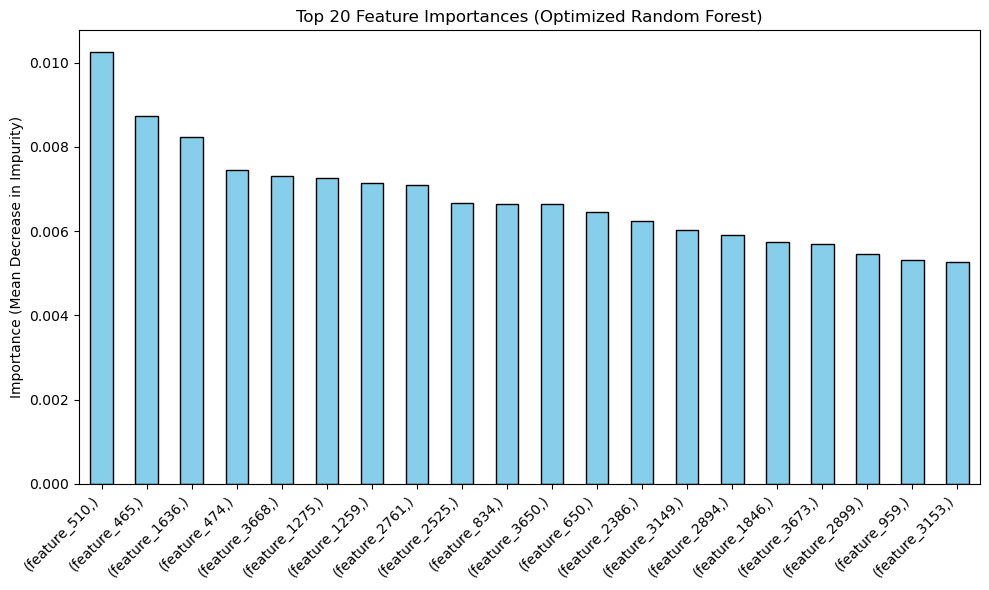

In [26]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import pandas as pd

# Random Forest tuning
param_grid_rf = {
    'n_estimators': [100, 200, 300, 400, 500],        # Number of trees (more is stable but slower)
    'max_depth': [None, 10, 20],       # Depth of tree (None = fully grown)
    'min_samples_split': [2, 5, 10],   # Min samples to create a split
    'min_samples_leaf': [1, 2, 4]      # Min samples required at a leaf node
}

# Initialize base model with balanced weights
rf_base = RandomForestClassifier(random_state=RANDOM_STATE, class_weight='balanced')

# GridSearch finds the best combination of parameters
grid_search_rf = GridSearchCV(
    rf_base, 
    param_grid_rf, 
    cv=5, 
    scoring=f1_scorer, 
    n_jobs=4,  # Use all available CPU cores
    verbose=1
)

print("Starting Random Forest Grid Search...")
grid_search_rf.fit(X_train, y_train)

best_rf_model = grid_search_rf.best_estimator_
print(f"Best RF Parameters: {grid_search_rf.best_params_}")

# Now tune the decision threshold using the optimized model
rf_tuned = TunedThresholdClassifierCV(best_rf_model, scoring=f1_scorer, cv=5)
rf_tuned.fit(X_train, y_train)

print(f"RF Optimal Threshold: {rf_tuned.best_threshold_:.3f}")

# Predict and evaluate on test set
y_pred_rf = rf_tuned.predict(X_test)
compute_and_print_metrics("RANDOM FOREST (GridSearch + Tuned Threshold)", y_test, y_pred_rf)


# See which biological features mattered most to the optimized model
importances = best_rf_model.feature_importances_
# If X_train was a DataFrame, use X_train.columns. If not, use indices or your original df.columns
feature_names = df.columns if hasattr(df, 'columns') else [f"Feature {i}" for i in range(X_train.shape[1])]

forest_importances = pd.Series(importances, index=feature_names).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
forest_importances.head(20).plot.bar(ax=ax, color='skyblue', edgecolor='black')
ax.set_title("Top 20 Feature Importances (Optimized Random Forest)")
ax.set_ylabel("Importance (Mean Decrease in Impurity)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### XGBoost (sklearn)

In [27]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, TunedThresholdClassifierCV
from sklearn.metrics import make_scorer, f1_score

param_grid_hgb = {
    'learning_rate': [0.01, 0.1, 0.2],
    'max_iter': [100, 200, 500, 1000],
    'max_depth': [3, 5, 10],
    'l2_regularization': [0.0, 0.1, 1]
}

# We use class_weight='balanced' natively (no manual calculation needed)
hgb_base = HistGradientBoostingClassifier(
    class_weight='balanced',
    random_state=RANDOM_STATE,
    scoring='loss' # Optimizes log-loss internally
)

# Define Scorer (Optimizing F1 for Lysogenic)
# Since HistGradientBoosting accepts strings, we don't strictly need LabelEncoder for y,
# but using the scorer with pos_label ensures clarity.
scorer = make_scorer(f1_score, pos_label="lysogenic")

print("Starting HistGradientBoosting Grid Search...")
grid_search_hgb = GridSearchCV(
    hgb_base, 
    param_grid_hgb, 
    cv=5, 
    scoring=scorer, 
    n_jobs=-1, # Adjust based on your available cores
    verbose=1
)

grid_search_hgb.fit(X_train, y_train)

best_hgb = grid_search_hgb.best_estimator_
print(f"Best HGB Params: {grid_search_hgb.best_params_}")

# Tune decision threshold on the optimized model
print("Tuning Decision Threshold...")
hgb_final = TunedThresholdClassifierCV(best_hgb, scoring=scorer, cv=5)
hgb_final.fit(X_train, y_train)

print(f"HGB Optimal Threshold: {hgb_final.best_threshold_:.3f}")

# HistGradientBoosting in sklearn handles string labels natively!
y_pred_hgb = hgb_final.predict(X_test)

compute_and_print_metrics("HistGradientBoosting (Sklearn's XGBoost)", y_test, y_pred_hgb)

Starting HistGradientBoosting Grid Search...


Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best HGB Params: {'l2_regularization': 1, 'learning_rate': 0.1, 'max_depth': 3, 'max_iter': 1000}
Tuning Decision Threshold...
HGB Optimal Threshold: 0.535

HistGradientBoosting (Sklearn's XGBoost) RESULTS
------------------------------
Sensitivity (Recall): 0.7795
Specificity:          0.9918
Accuracy:             0.9194
F1-Score:             0.8684
MCC:                  0.8224
------------------------------
Confusion Matrix:
                 Pred lytic  Pred lysogenic
Actual lytic       243               2
Actual lysogenic    28              99


In [28]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import make_scorer, f1_score

hgb_test = HistGradientBoostingClassifier(
    class_weight='balanced',
    random_state=0,
    scoring='loss',
    l2_regularization=1,
    learning_rate=0.01,
    max_depth=3,
    max_iter=1000
)

hgb_test.fit(X_train, y_train)
y_pred_test_hgb = hgb_test.predict(X_test)

compute_and_print_metrics("HistGradientBoosting (Sklearn's XGBoost)", y_test, y_pred_test_hgb)


HistGradientBoosting (Sklearn's XGBoost) RESULTS
------------------------------
Sensitivity (Recall): 0.7953
Specificity:          0.9592
Accuracy:             0.9032
F1-Score:             0.8487
MCC:                  0.7819
------------------------------
Confusion Matrix:
                 Pred lytic  Pred lysogenic
Actual lytic       235              10
Actual lysogenic    26             101


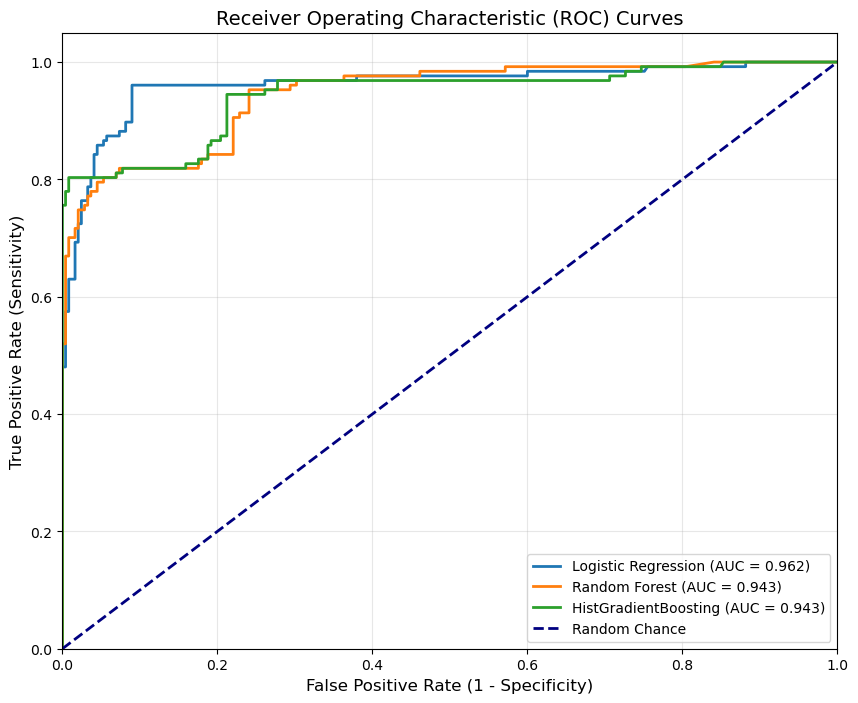

In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# # 1. Define the models you want to plot
best_lr_model = LogisticRegression(
    max_iter=5000, 
    random_state=RANDOM_STATE, 
    class_weight='balanced', 
    C=0.3593813663804626,
    solver='lbfgs'
)
# Best RF Parameters: {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 100}
best_rf_model = rf_base = RandomForestClassifier(
    random_state=RANDOM_STATE, 
    class_weight='balanced', 
    max_depth=10,
    min_samples_leaf=4,
    min_samples_split=2, 
    n_estimators=100
)

best_hgb = HistGradientBoostingClassifier(
    class_weight='balanced',
    random_state=0,
    scoring='loss',
    l2_regularization=1,
    learning_rate=0.01,
    max_depth=3,
    max_iter=1000
)

# models_dict = {
#     "Logistic Regression": best_lr_model,
#     "Random Forest": best_rf_model,
#     "HistGradientBoosting": best_hgb
# }

plt.figure(figsize=(10, 8))

for name, model in models_dict.items():
    # Check if the model is fitted; if not, print a warning and skip
    if not hasattr(model, "classes_"):
        print(f"Warning: Model '{name}' appears to be unfitted (missing 'classes_'). Skipping.")
        continue

    # Identify the index of the positive class ('lysogenic')
    pos_label = "lysogenic"
    # TunedThresholdClassifierCV exposes classes_ from the underlying estimator
    if pos_label in model.classes_:
        pos_idx = list(model.classes_).index(pos_label)
    else:
        pos_idx = 1 
    
    # Get predicted probabilities
    # Note: TunedThresholdClassifierCV.predict_proba delegates to the underlying estimator
    y_proba = model.predict_proba(X_test)[:, pos_idx]
    
    # Calculate ROC curve and AUC
    fpr, tpr, thresholds = roc_curve(y_test, y_proba, pos_label=pos_label)
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.3f})')

# Formatting the plot
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Chance')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curves', fontsize=14)
plt.legend(loc="lower right", fontsize=10)
plt.grid(alpha=0.3)
plt.show()

### Test with Normalization

In [37]:

#X_normalized = preprocessing.normalize(X_train, norm='l2')
# Scale data
normalizer = preprocessing.Normalizer()
X_train = normalizer.transform(X_train)
X_test = normalizer.transform(X_test)

In [38]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import make_scorer, f1_score

hgb_norm = HistGradientBoostingClassifier(
    class_weight='balanced',
    random_state=0,
    scoring='loss',
    l2_regularization=1,
    learning_rate=0.01,
    max_depth=3,
    max_iter=1000
)

hgb_norm.fit(X_train, y_train)
y_pred_test_hgb_norm = hgb_norm.predict(X_test)

compute_and_print_metrics("HistGradientBoosting (Sklearn's XGBoost)", y_test, y_pred_test_hgb_norm)


HistGradientBoosting (Sklearn's XGBoost) RESULTS
------------------------------
Sensitivity (Recall): 0.7874
Specificity:          0.9592
Accuracy:             0.9005
F1-Score:             0.8439
MCC:                  0.7757
------------------------------
Confusion Matrix:
                 Pred lytic  Pred lysogenic
Actual lytic       235              10
Actual lysogenic    27             100


Training Logistic Regression...
Training Random Forest...
Training HistGradientBoosting...


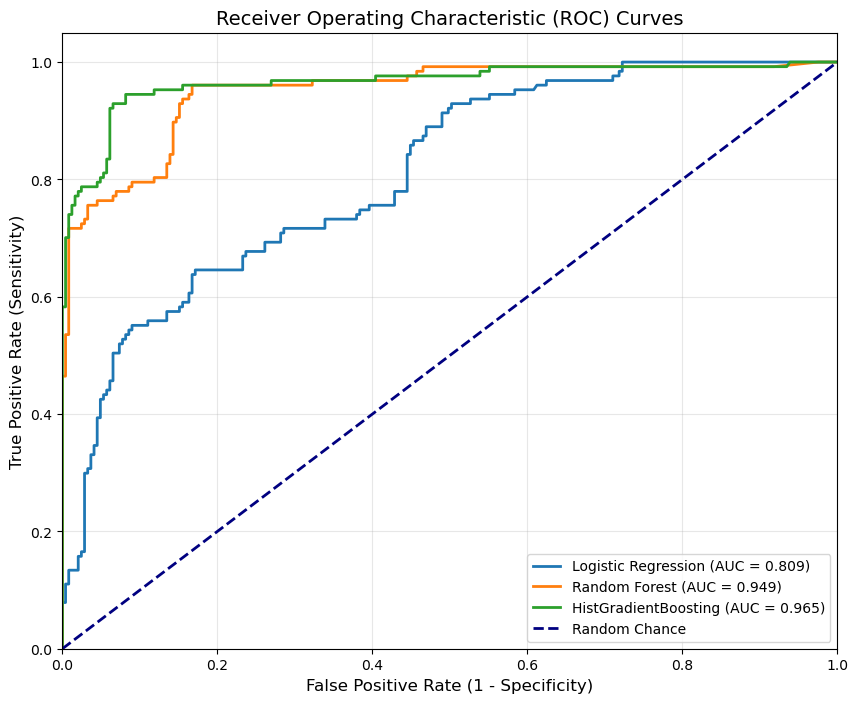

In [39]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier # Added missing import
from sklearn.linear_model import LogisticRegression

# Assume X_train, y_train, X_test, y_test, and RANDOM_STATE are defined in your previous code
# RANDOM_STATE = 42 

# 1. Define the models
best_lr_model_norm = LogisticRegression(
    max_iter=5000, 
    random_state=RANDOM_STATE, 
    class_weight='balanced', 
    C=0.3593813663804626,
    solver='lbfgs'
)

best_rf_model_norm = RandomForestClassifier(
    random_state=RANDOM_STATE, 
    class_weight='balanced', 
    max_depth=10,
    min_samples_leaf=4,
    min_samples_split=2, 
    n_estimators=100
)

best_hgb_norm = HistGradientBoostingClassifier(
    class_weight='balanced',
    random_state=0,
    scoring='loss',
    l2_regularization=1,
    learning_rate=0.01,
    max_depth=3,
    max_iter=1000
)

models_dict = {
    "Logistic Regression": best_lr_model_norm,
    "Random Forest": best_rf_model_norm,
    "HistGradientBoosting": best_hgb_norm
}

plt.figure(figsize=(10, 8))

for name, model in models_dict.items():
    # --- CRITICAL FIX: Fit the model if it hasn't been fitted yet ---
    if not hasattr(model, "classes_"):
        print(f"Training {name}...")
        model.fit(X_train, y_train) 
    # ----------------------------------------------------------------

    # Identify the index of the positive class ('lysogenic')
    pos_label = "lysogenic"
    
    if pos_label in model.classes_:
        pos_idx = list(model.classes_).index(pos_label)
    else:
        # Fallback if specific label string isn't found (e.g. if data is 0/1)
        pos_idx = 1 
    
    # Get predicted probabilities
    y_proba = model.predict_proba(X_test)[:, pos_idx]
    
    # Calculate ROC curve and AUC
    fpr, tpr, thresholds = roc_curve(y_test, y_proba, pos_label=pos_label)
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.3f})')

# Formatting the plot
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Chance')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curves', fontsize=14)
plt.legend(loc="lower right", fontsize=10)
plt.grid(alpha=0.3)
plt.show()

In [40]:
from sklearn.model_selection import GridSearchCV

param_grid = [
    {
    'C' : np.logspace(-4,4,10),
    'solver': ['lbfgs','liblinear'],
}
]
# Initialize base model (balanced weights are crucial here)
lr_base = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE, class_weight='balanced')
# GridSearch tries all combinations in param_grid
# We use the same scoring (f1_scorer) to pick the best params
grid_search = GridSearchCV(
    lr_base, 
    param_grid, 
    cv=5, 
    scoring=f1_scorer, 
    n_jobs=-1,  # Use all CPU cores
    verbose=1
)


print("Starting Grid Search...")
grid_search.fit(X_train, y_train)

best_lr_model = grid_search.best_estimator_
print(f"Best Hyperparameters found: {grid_search.best_params_}")


# Now we take the optimized model and fine-tune the decision threshold
# TunedThresholdClassifierCV will use internal CV to find the cutoff
lr_tuned = TunedThresholdClassifierCV(best_lr_model, scoring=f1_scorer, cv=5)
lr_tuned.fit(X_train, y_train)

print(f"LR Optimal Threshold: {lr_tuned.best_threshold_:.3f}")

# This uses the Best Hyperparameters AND the Best Threshold
y_pred_lr = lr_tuned.predict(X_test)

compute_and_print_metrics("LOGISTIC REGRESSION (GridSearch + Tuned Threshold)", y_test, y_pred_lr)

Starting Grid Search...
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Hyperparameters found: {'C': np.float64(10000.0), 'solver': 'liblinear'}
LR Optimal Threshold: 0.616

LOGISTIC REGRESSION (GridSearch + Tuned Threshold) RESULTS
------------------------------
Sensitivity (Recall): 0.7717
Specificity:          0.9633
Accuracy:             0.8978
F1-Score:             0.8376
MCC:                  0.7699
------------------------------
Confusion Matrix:
                 Pred lytic  Pred lysogenic
Actual lytic       236               9
Actual lysogenic    29              98
